# Object-Oriented Programming in Python

**Object-oriented programming (OOP)** groups data and the functions that work on that data into one unit: a **class**. An **object** is one instance of a class. Most Python libraries that you use in this course are built from classes: a pandas `DataFrame`, a scikit-learn model, a PyTorch `nn.Module`.

**After this lesson you can:**

1. Define classes with attributes, methods and properties.
2. Explain instance attributes and class attributes.
3. Use inheritance, abstract base classes and polymorphism.
4. Implement special methods (`__repr__`, `__eq__`, `__len__`, ...).

## 1. A First Class

- `__init__` runs when you create an object. It sets the **instance attributes**.
- `self` is the object itself. Python passes it automatically as the first argument of every method.
- A **class attribute** belongs to the class and is shared by all instances.

In [1]:
class BankAccount:
    bank_name = "Course Bank"                # class attribute: shared

    def __init__(self, owner: str, balance: float = 0.0):
        self.owner = owner                  # instance attributes: one copy per object
        self.balance = balance
        self.history: list[tuple[str, float]] = []

    def deposit(self, amount: float) -> None:
        if amount <= 0:
            raise ValueError("deposit must be positive")
        self.balance += amount
        self.history.append(("deposit", amount))

    def withdraw(self, amount: float) -> None:
        if amount > self.balance:
            raise ValueError(f"insufficient funds: balance {self.balance:.2f}")
        self.balance -= amount
        self.history.append(("withdraw", amount))

a = BankAccount("Ayse", 100)
b = BankAccount("Mert")
a.deposit(50)
a.withdraw(30)
print(a.owner, a.balance, a.history)
print(b.owner, b.balance, "| same bank:", a.bank_name == b.bank_name == BankAccount.bank_name)
try:
    b.withdraw(10)
except ValueError as err:
    print("error:", err)

Ayse 120 [('deposit', 50), ('withdraw', 30)]
Mert 0.0 | same bank: True
error: insufficient funds: balance 0.00


## 2. Encapsulation and Properties

Python has no private attributes. By convention, a leading underscore (`_balance`) means "internal: do not use from outside". A **property** looks like an attribute but runs a method. It can validate values or compute them on demand.

In [2]:
class Temperature:
    def __init__(self, celsius: float):
        self.celsius = celsius               # goes through the setter below

    @property
    def celsius(self) -> float:
        return self._celsius

    @celsius.setter
    def celsius(self, value: float) -> None:
        if value < -273.15:
            raise ValueError("below absolute zero")
        self._celsius = value

    @property
    def fahrenheit(self) -> float:          # computed, read-only
        return self._celsius * 9 / 5 + 32

t = Temperature(25)
print(t.celsius, "°C =", t.fahrenheit, "°F")
t.celsius = 100
print(t.celsius, "°C =", t.fahrenheit, "°F")
try:
    t.celsius = -300
except ValueError as err:
    print("error:", err)

25 °C = 77.0 °F
100 °C = 212.0 °F
error: below absolute zero


## 3. Special Methods

**Special methods** (also called *dunder* methods, for "double underscore") connect your class to Python syntax:

| Method | Called by |
| :--- | :--- |
| `__repr__` | `repr(obj)`, the notebook display |
| `__str__` | `str(obj)`, `print(obj)` |
| `__eq__`, `__lt__` | `==`, `<` (and `sorted()`) |
| `__len__`, `__getitem__`, `__iter__` | `len()`, `obj[i]`, `for` loops |
| `__add__` | `+` |

In [3]:
from functools import total_ordering

@total_ordering                               # creates <=, >, >= from __eq__ and __lt__
class Money:
    def __init__(self, amount: float, currency: str = "EUR"):
        self.amount, self.currency = round(amount, 2), currency

    def __repr__(self):
        return f"Money({self.amount}, {self.currency!r})"

    def __add__(self, other: "Money") -> "Money":
        if self.currency != other.currency:
            raise ValueError("currency mismatch")
        return Money(self.amount + other.amount, self.currency)

    def __eq__(self, other):
        return (self.amount, self.currency) == (other.amount, other.currency)

    def __lt__(self, other):
        return self.amount < other.amount

class Cart:
    def __init__(self):
        self.items: list[tuple[str, Money]] = []

    def add(self, name: str, price: Money):
        self.items.append((name, price))

    def __len__(self):
        return len(self.items)

    def __iter__(self):
        return iter(self.items)

    def total(self) -> Money:
        return sum((price for _, price in self.items), Money(0))

cart = Cart()
cart.add("book", Money(12.5))
cart.add("pen", Money(1.2))
cart.add("bag", Money(30))
print(len(cart), "items:", [name for name, _ in cart])
print("total:", cart.total(), "| cheapest:", min(p for _, p in cart), "| sorted:", sorted(p for _, p in cart))

3 items: ['book', 'pen', 'bag']
total: Money(43.7, 'EUR') | cheapest: Money(1.2, 'EUR') | sorted: [Money(1.2, 'EUR'), Money(12.5, 'EUR'), Money(30, 'EUR')]


## 4. Inheritance, Abstract Classes and Polymorphism

A **subclass** inherits the attributes and methods of its **base class** and can override them. An **abstract base class** (ABC) defines methods that every subclass must implement. **Polymorphism** means that code can use any subclass through the same interface.

The example defines a tiny machine-learning interface, `Regressor`, with `fit()` and `predict()`, similar to scikit-learn. Two subclasses implement it differently.

In [4]:
from abc import ABC, abstractmethod

import numpy as np

class Regressor(ABC):
    def __init__(self):
        self.is_fitted = False

    @abstractmethod
    def fit(self, x: np.ndarray, y: np.ndarray) -> "Regressor": ...

    @abstractmethod
    def predict(self, x: np.ndarray) -> np.ndarray: ...

    def score(self, x, y) -> float:            # shared by all subclasses: R^2
        residual = ((y - self.predict(x)) ** 2).sum()
        return 1 - residual / ((y - y.mean()) ** 2).sum()

    def __repr__(self):
        return f"{type(self).__name__}(fitted={self.is_fitted})"

class MeanRegressor(Regressor):
    def fit(self, x, y):
        self.mean_ = y.mean()
        self.is_fitted = True
        return self

    def predict(self, x):
        return np.full(len(x), self.mean_)

class LinearRegressor(Regressor):
    def fit(self, x, y):
        X = np.column_stack([np.ones(len(x)), x])
        self.coef_ = np.linalg.lstsq(X, y, rcond=None)[0]   # least squares
        self.is_fitted = True
        return self

    def predict(self, x):
        return self.coef_[0] + self.coef_[1] * x

try:
    Regressor()
except TypeError as err:
    print("cannot instantiate an ABC:", err)

rng = np.random.default_rng(0)
x = rng.uniform(0, 10, 60)
y = 3 + 2 * x + rng.normal(0, 2, 60)          # synthetic data with a known line
models = [MeanRegressor().fit(x, y), LinearRegressor().fit(x, y)]
for m in models:                               # polymorphism: same calls, different classes
    print(f"{m!r:<32} R^2 = {m.score(x, y):.3f}")
print("learned line: y = {:.2f} + {:.2f} x".format(*models[1].coef_))

cannot instantiate an ABC: Can't instantiate abstract class Regressor without an implementation for abstract methods 'fit', 'predict'
MeanRegressor(fitted=True)       R^2 = 0.000
LinearRegressor(fitted=True)     R^2 = 0.895
learned line: y = 3.24 + 1.99 x


## 5. Visualise Polymorphism

Both models answer the same `predict()` call. The plot shows their different answers on the same data.

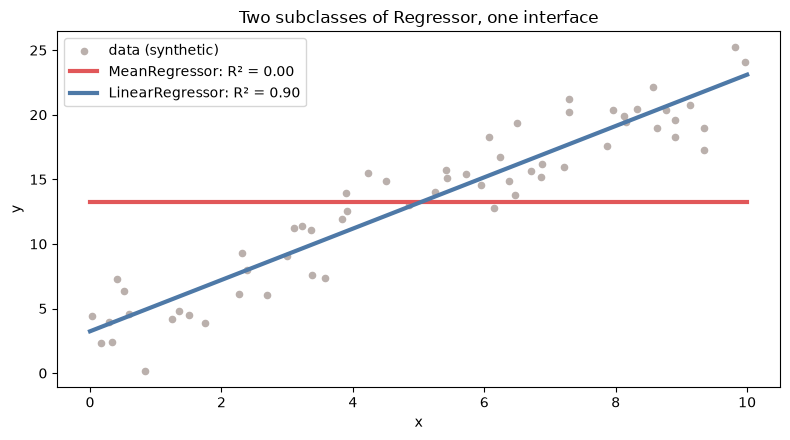

In [5]:
import matplotlib.pyplot as plt

grid = np.linspace(0, 10, 100)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(x, y, s=20, color="#BAB0AC", label="data (synthetic)")
for m, color in zip(models, ["#E15759", "#4E79A7"]):
    ax.plot(grid, m.predict(grid), lw=3, color=color, label=f"{type(m).__name__}: R² = {m.score(x, y):.2f}")
ax.set(title="Two subclasses of Regressor, one interface", xlabel="x", ylabel="y")
ax.legend()
plt.tight_layout()
plt.show()

*Insight: Use classes when data and behaviour belong together and you need several objects with the same interface. Prefer composition (an object that contains other objects) over deep inheritance trees, and keep simple data in dataclasses (Lesson 14).*

## Real-World Use Case or Analogy

A class is like the **blueprint of a car model**; each object is one car built from it, with its own colour and mileage. An abstract base class is like a **standard that every car must meet**: it must have brakes and a steering wheel, but each manufacturer builds them differently.

scikit-learn uses exactly this design: every model has `fit()` and `predict()`, so a pipeline can swap a linear model for a random forest without other changes (M16). PyTorch models are subclasses of `nn.Module` that implement `forward()` (M20).